# Where did Albertans vote for a separation referendum?
### A spatial look at Question 10 of the 19 October 2026 Alberta referendum

*Joseph and Zarif.* Adapted from a collaborator's Colab notebook. The command-line version of the same analysis is `scripts/06-spatial_analysis.py`.

---

**Who this is for.** You do not need to read code to follow this notebook. Each grey box is code; the text, tables and figures under it are what it produced. Skip the code and read the text. The same analysis is in `notebooks/06-spatial_analysis.qmd` (Quarto), rendered as a web page in `notebooks/06-spatial_analysis.html`, where the code boxes can be collapsed.

**The question on the ballot.** Question 10 asked:

> *Should Alberta remain a province of Canada, or should the Government of Alberta commence the legal process required under the Canadian Constitution to hold a binding provincial referendum on whether or not Alberta should separate from Canada?*

Voters chose **Option 1** (remain a province) or **Option 2** (start the legal process toward a binding separation referendum). The question was not itself binding. Throughout, **"Option 2 share"** means Option 2 votes as a percentage of valid Option 1 + Option 2 votes in a riding. Declined and rejected ballots are left out.

**What this notebook asks.**

1. Where was Option 2 strongest and weakest? (sections 2 to 4)
2. Is support geographically clustered, more than chance would produce? (section 5)
3. Is that clustering just the city-versus-country divide, or is there more to it? (section 6)
4. Where exactly are the clusters? (section 7)
5. Did ridings with higher turnout vote differently? (section 8)

The findings are summarised in section 9. Technical terms are explained in the glossary at the end.

## 0. Setup
Loads the tools and settings the rest of the notebook uses. Nothing to read here.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import Normalize

from spatial import (LISA_COLOURS, REGION_COLOURS, REGION_ORDER, knn_weights, load_q10,
                     local_moran, moran_test, morans_i, queen_weights)

N_PERMUTATIONS = 9999   # random reshuffles used for every significance test
ALPHA = 0.05            # significance threshold
NORM = Normalize(vmin=5, vmax=55)   # one colour scale for every Option 2 map
CMAP = "YlOrRd"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})

def note(text):
    """Show a caption written from the results, so the numbers never go stale."""
    display(Markdown(text))

def pct(x, digits=1):
    return f"{x:.{digits}f}%"

## 1. The data
Three files are combined:

- **Results.** Official Elections Alberta counts for each of the 87 electoral divisions (ridings), cleaned by `scripts/03-clean_data.py`.
- **Boundaries.** The Government of Alberta's map of the 87 divisions created in 2017, which were the divisions in use in 2026. Lines are slightly simplified to keep the file small.
- **Regions.** A label putting each riding in one of five regions. The labels came from the original collaborator notebook and have not been checked against an official source.

The code stops with an error if the vote totals differ from the figures Elections Alberta published on 29 October 2026, so the numbers below are the official ones.

In [2]:
gdf = load_q10()
y = gdf["option2_pct"].to_numpy()

prov_o1, prov_o2 = gdf["choice_1_votes"].sum(), gdf["choice_2_votes"].sum()
prov_share = 100 * prov_o2 / (prov_o1 + prov_o2)
over_50 = gdf[gdf["option2_pct"] > 50].sort_values("option2_pct", ascending=False)

note(f"""**Province-wide:** {prov_o1:,} votes for Option 1 and {prov_o2:,} for Option 2, so Option 2 won
**{pct(prov_share, 2)}** of valid votes. Across the {len(gdf)} ridings, the Option 2 share ranged from
{pct(y.min())} to {pct(y.max())}. **{len(over_50)} ridings** gave Option 2 a majority:""")
over_50.assign(ed_name=over_50["ed_name"].str.title())[["ed_name", "region", "choice_1_votes", "choice_2_votes", "option2_pct"]].rename(columns={
    "ed_name": "Riding", "region": "Region", "choice_1_votes": "Option 1 votes",
    "choice_2_votes": "Option 2 votes", "option2_pct": "Option 2 share (%)"}).round(1).set_index("Riding")

**Province-wide:** 1,556,316 votes for Option 1 and 520,233 for Option 2, so Option 2 won
**25.05%** of valid votes. Across the 87 ridings, the Option 2 share ranged from
9.3% to 50.9%. **2 ridings** gave Option 2 a majority:

,Region,Option 1 votes,Option 2 votes,Option 2 share (%)
Riding,,,,
Rimbey-Rocky Mountain House-Sundre,Central,12220,12687,50.9
Central Peace-Notley,North,6409,6528,50.5


### What we mean by "region"
"Edmonton" and "Calgary" include only ridings inside those cities. Suburbs and nearby towns, such as St. Albert, Sherwood Park, Airdrie and Chestermere, are counted as **Central**. Keep this in mind when comparing regions.

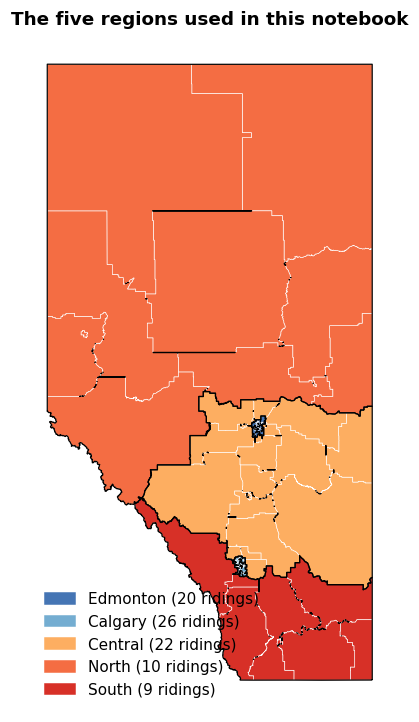

In [3]:
fig, ax = plt.subplots(figsize=(6, 8))
for region in REGION_ORDER:
    gdf[gdf["region"] == region].plot(ax=ax, color=REGION_COLOURS[region], edgecolor="white", linewidth=0.4)
gdf.dissolve("region").boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.legend(handles=[mpatches.Patch(color=REGION_COLOURS[r], label=f"{r} ({(gdf['region'] == r).sum()} ridings)")
                   for r in REGION_ORDER], loc="lower left", frameon=False)
ax.set_title("The five regions used in this notebook")
ax.set_axis_off()
plt.show()

## 2. The map
**How to read it.** Each shape is one riding, coloured by its Option 2 share: pale yellow means little support, dark red means more. Black lines mark region borders. Stars mark the ridings where Option 2 won a majority. City ridings are too small to see on the provincial map, so Calgary and Edmonton are enlarged on the right with each riding's share printed on it.

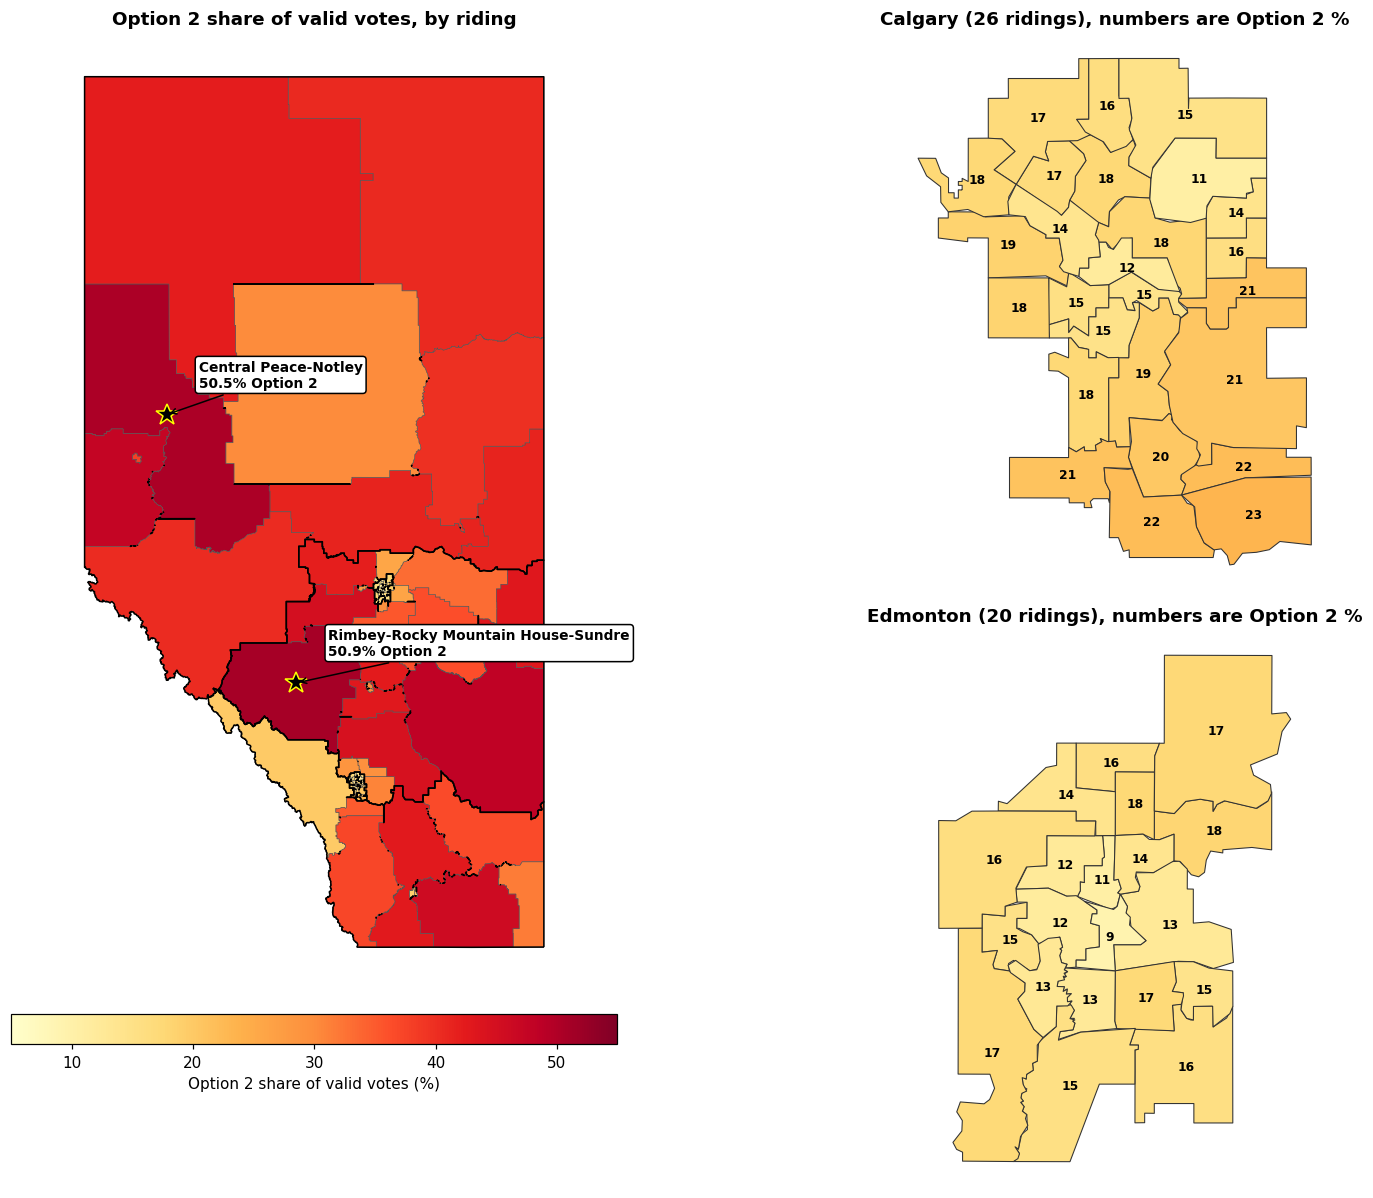

**What it shows.** The strongest Option 2 result was Rimbey-Rocky Mountain House-Sundre (50.9%)
and the weakest was Edmonton-Strathcona (9.3%). No riding in Calgary or Edmonton gave
Option 2 more than 23.3%, below the provincial result of 25.05%. The darker
areas are rural: the Peace Country in the northwest, west-central Alberta and much of the east. The pale strip
along the Rockies is Banff-Kananaskis.

In [4]:
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1.0])
ax_main, ax_cal, ax_edm = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])

gdf.plot(column="option2_pct", cmap=CMAP, norm=NORM, edgecolor="#555555", linewidth=0.4, ax=ax_main)
gdf.dissolve("region").boundary.plot(ax=ax_main, color="black", linewidth=1.0)
for _, r in over_50.iterrows():
    ax_main.plot(r["lon"], r["lat"], marker="*", markersize=15, color="black", markeredgecolor="yellow")
    ax_main.annotate(f"{r['ed_name'].title()}\n{r['option2_pct']:.1f}% Option 2", xy=(r["lon"], r["lat"]),
                     xytext=(r["lon"] + 0.7, r["lat"] + 0.35), fontsize=9, fontweight="bold",
                     bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="black"),
                     arrowprops=dict(arrowstyle="->", color="black"))
ax_main.set_title("Option 2 share of valid votes, by riding")
ax_main.set_axis_off()
sm = plt.cm.ScalarMappable(norm=NORM, cmap=CMAP)
fig.colorbar(sm, ax=ax_main, orientation="horizontal", shrink=0.6, pad=0.02,
             label="Option 2 share of valid votes (%)")

for ax, region in ((ax_cal, "Calgary"), (ax_edm, "Edmonton")):
    sub = gdf[gdf["region"] == region]
    sub.plot(column="option2_pct", cmap=CMAP, norm=NORM, edgecolor="#333333", linewidth=0.7, ax=ax)
    for _, r in sub.iterrows():
        ax.text(r["lon"], r["lat"], f"{r['option2_pct']:.0f}", fontsize=8, ha="center", va="center", fontweight="bold")
    ax.set_title(f"{region} ({len(sub)} ridings), numbers are Option 2 %")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

hi, lo = gdf.loc[gdf["option2_pct"].idxmax()], gdf.loc[gdf["option2_pct"].idxmin()]
city = gdf[gdf["region"].isin(["Calgary", "Edmonton"])]
note(f"""**What it shows.** The strongest Option 2 result was {hi['ed_name'].title()} ({pct(hi['option2_pct'])})
and the weakest was {lo['ed_name'].title()} ({pct(lo['option2_pct'])}). No riding in Calgary or Edmonton gave
Option 2 more than {pct(city['option2_pct'].max())}, below the provincial result of {pct(prov_share, 2)}. The darker
areas are rural: the Peace Country in the northwest, west-central Alberta and much of the east. The pale strip
along the Rockies is Banff-Kananaskis.""")

## 3. Why the map exaggerates Option 2
Rural ridings cover huge areas with few voters; city ridings are tiny with many. A map coloured by riding therefore makes Option 2 look stronger than it was, because most of the coloured area belongs to rural ridings. The chart below compares each region's share of Alberta's land with its share of the votes.

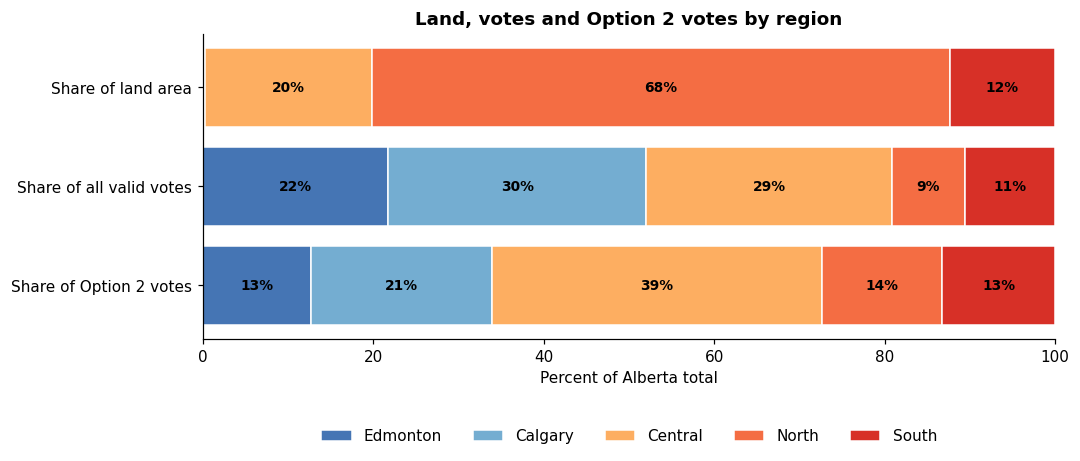

**What it shows.** The North covers 68% of Alberta's land but
cast only 9% of the valid votes. Calgary and Edmonton
together cover well under 1% of the land but cast 52% of the votes, and
34% of all Option 2 votes. The largest single source of Option 2 votes was
Central Alberta (39%).

,Ridings,Area (km²),Valid votes,Option 2 votes,Option 2 share (%)
Region,,,,,
Edmonton,20,781,451834,65797,14.6
Calgary,26,848,629038,110893,17.6
Central,22,130006,598218,201154,33.6
North,10,449797,176672,73485,41.6
South,9,82152,220787,68904,31.2


In [5]:
by_region = gdf.groupby("region").agg(
    ridings=("ed_code", "size"), area_km2=("area_km2", "sum"),
    valid_votes=("total", "sum"), option2_votes=("choice_2_votes", "sum")).reindex(REGION_ORDER)
shares = 100 * by_region[["area_km2", "valid_votes", "option2_votes"]] / by_region[["area_km2", "valid_votes", "option2_votes"]].sum()
shares.columns = ["Share of land area", "Share of all valid votes", "Share of Option 2 votes"]

fig, ax = plt.subplots(figsize=(10, 3.6))
left = np.zeros(3)
for region in REGION_ORDER:
    vals = shares.loc[region].to_numpy()
    ax.barh(shares.columns, vals, left=left, color=REGION_COLOURS[region], edgecolor="white", label=region)
    for i, v in enumerate(vals):
        if v >= 4:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, fontweight="bold")
    left += vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percent of Alberta total")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
ax.set_title("Land, votes and Option 2 votes by region")
plt.show()

cities = shares.loc[["Calgary", "Edmonton"]].sum()
note(f"""**What it shows.** The North covers {pct(shares.loc['North', 'Share of land area'], 0)} of Alberta's land but
cast only {pct(shares.loc['North', 'Share of all valid votes'], 0)} of the valid votes. Calgary and Edmonton
together cover well under 1% of the land but cast {pct(cities['Share of all valid votes'], 0)} of the votes, and
{pct(cities['Share of Option 2 votes'], 0)} of all Option 2 votes. The largest single source of Option 2 votes was
Central Alberta ({pct(shares.loc['Central', 'Share of Option 2 votes'], 0)}).""")

table = by_region.assign(**{"Option 2 share (%)": 100 * by_region["option2_votes"] / by_region["valid_votes"]})
table = table.rename(columns={"ridings": "Ridings", "area_km2": "Area (km²)", "valid_votes": "Valid votes",
                              "option2_votes": "Option 2 votes"})
table.index.name = "Region"
table.round({"Area (km²)": 0, "Option 2 share (%)": 1}).astype({"Area (km²)": int})

## 4. Every riding, ranked
**How to read it.** On the left, every riding is a bar, longest at the top, coloured by region. The dotted line is the province-wide result and the red dashed line is 50%. On the right, each box summarises one region: the thick line is the middle riding (the median), the box holds the middle half of ridings, and the whiskers reach the rest (dots are unusual ridings).

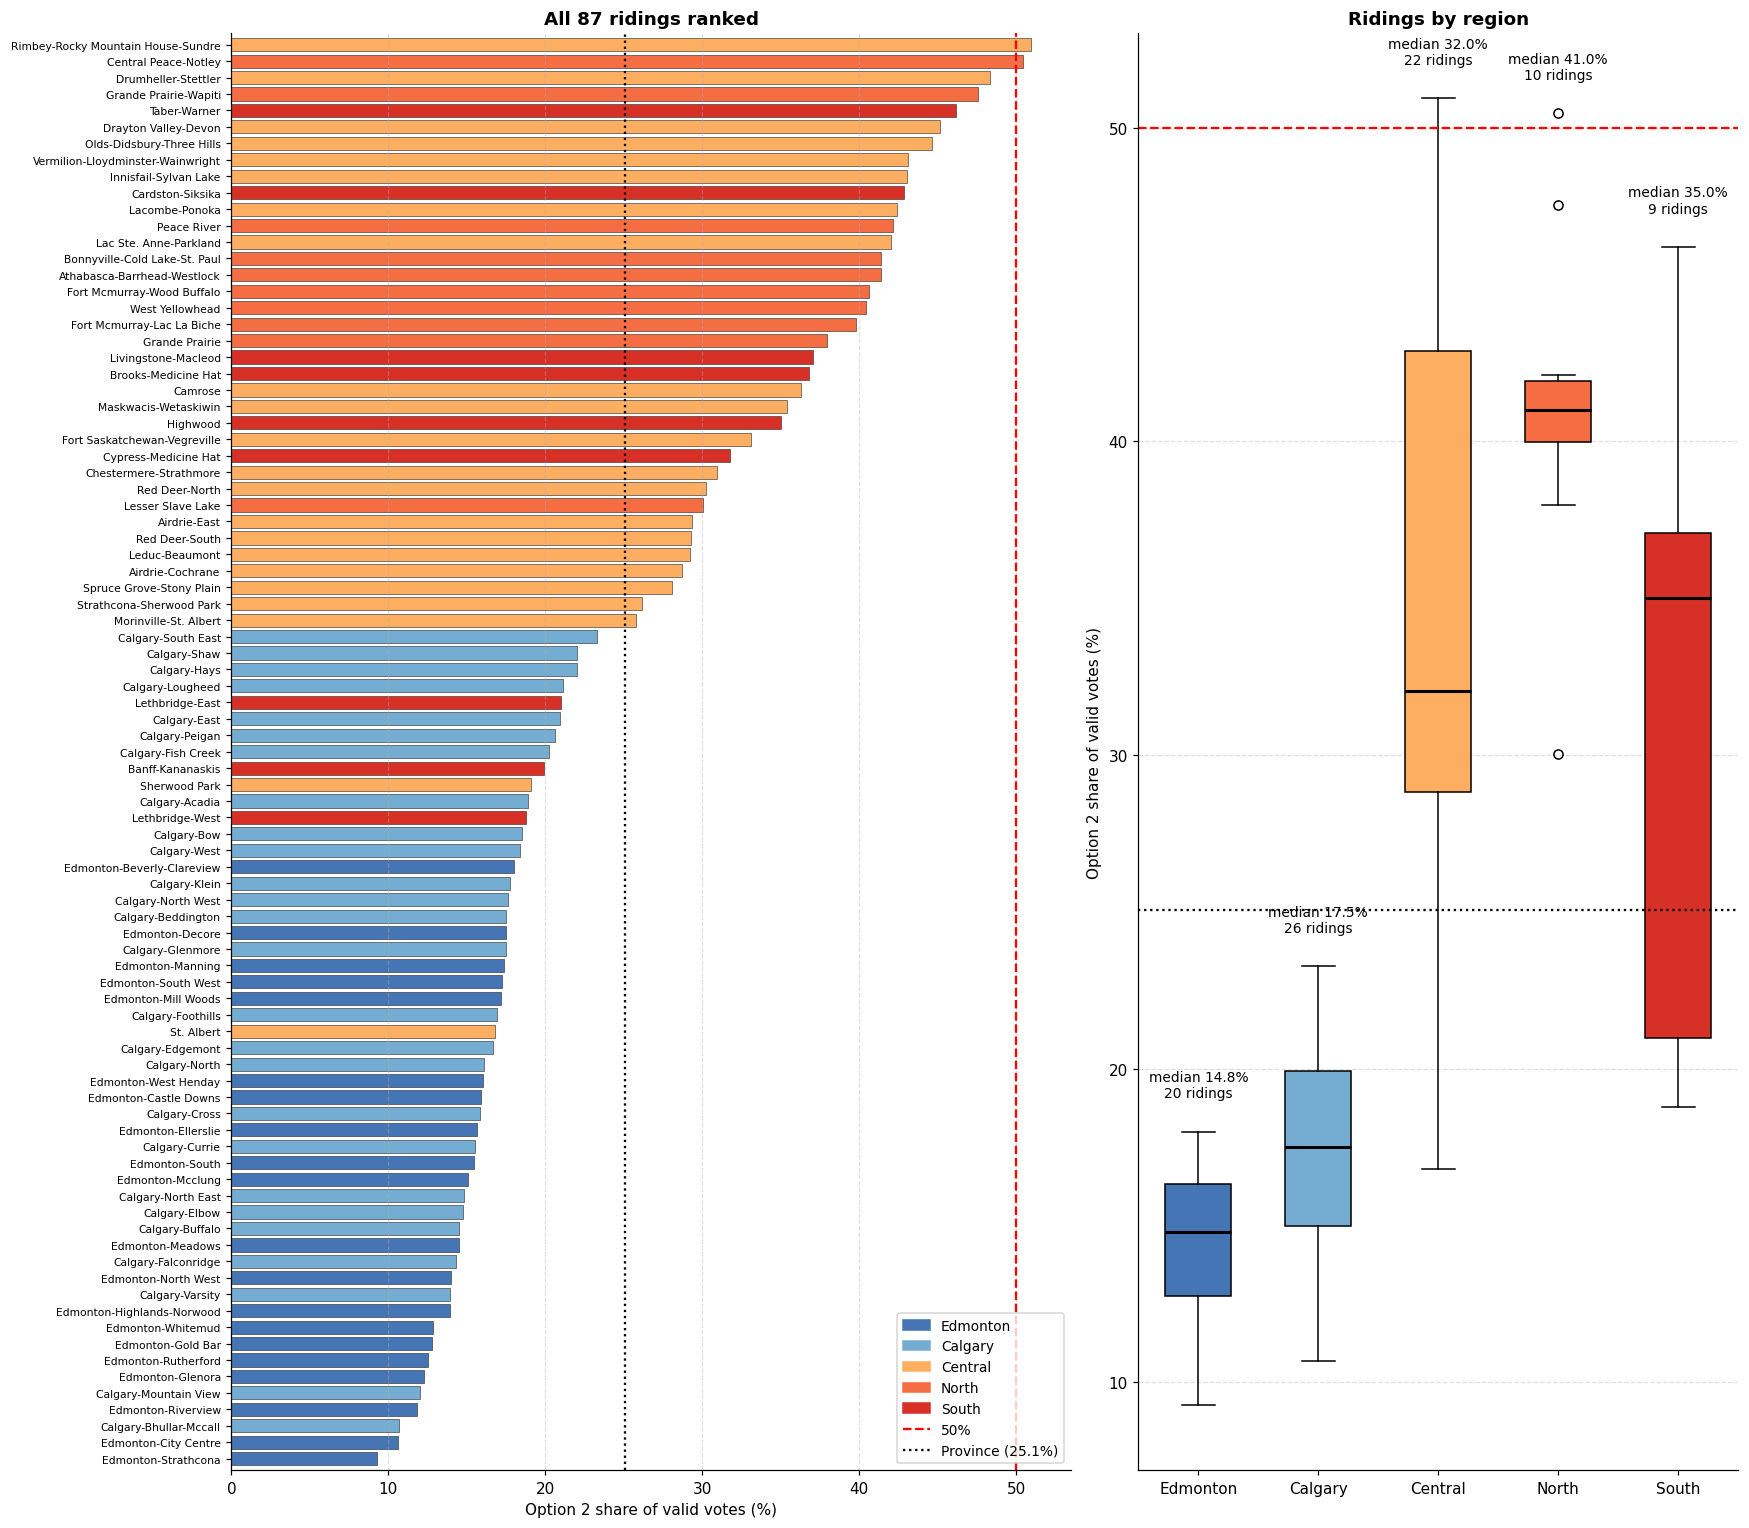

**What it shows.** All 46 Calgary and Edmonton ridings are below the provincial result; Calgary's
south and east come closest. All of the top 20 ridings are outside the two cities
(North: 9, Central: 8, South: 3). Median ridings range from 14.8% (Edmonton) to
41.0% (North). Central Alberta is the most varied region, from its suburbs near Edmonton
and Calgary (low Option 2) to rural ridings near or above 50%.

In [6]:
ranked = gdf.sort_values("option2_pct")
fig, (ax_bar, ax_box) = plt.subplots(1, 2, figsize=(16, 14), gridspec_kw={"width_ratios": [1.4, 1.0]})

ax_bar.barh(np.arange(len(ranked)), ranked["option2_pct"], color=ranked["region"].map(REGION_COLOURS),
            edgecolor="#333333", linewidth=0.4, height=0.8)
ax_bar.axvline(50, color="red", linestyle="--", linewidth=1.5)
ax_bar.axvline(prov_share, color="black", linestyle=":", linewidth=1.5)
ax_bar.set_yticks(np.arange(len(ranked)))
ax_bar.set_yticklabels(ranked["ed_name"].str.title(), fontsize=7)
ax_bar.set_ylim(-0.7, len(ranked) - 0.3)
ax_bar.set_xlabel("Option 2 share of valid votes (%)")
ax_bar.set_title("All 87 ridings ranked")
handles = [mpatches.Patch(color=REGION_COLOURS[r], label=r) for r in REGION_ORDER]
handles += [plt.Line2D([0], [0], color="red", linestyle="--", label="50%"),
            plt.Line2D([0], [0], color="black", linestyle=":", label=f"Province ({prov_share:.1f}%)")]
ax_bar.legend(handles=handles, loc="lower right", fontsize=9)
ax_bar.grid(axis="x", linestyle="--", alpha=0.4)

data = [gdf.loc[gdf["region"] == r, "option2_pct"] for r in REGION_ORDER]
bp = ax_box.boxplot(data, tick_labels=REGION_ORDER, patch_artist=True, widths=0.55)
for patch, r in zip(bp["boxes"], REGION_ORDER):
    patch.set_facecolor(REGION_COLOURS[r])
for med in bp["medians"]:
    med.set(color="black", linewidth=2)
for i, d in enumerate(data, start=1):
    ax_box.text(i, d.max() + 1, f"median {d.median():.1f}%\n{len(d)} ridings", ha="center", va="bottom", fontsize=9)
ax_box.axhline(50, color="red", linestyle="--", linewidth=1.5)
ax_box.axhline(prov_share, color="black", linestyle=":", linewidth=1.5)
ax_box.set_ylabel("Option 2 share of valid votes (%)")
ax_box.set_title("Ridings by region")
ax_box.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

med = gdf.groupby("region")["option2_pct"].median()
top20 = ranked.tail(20)
n_city_below = (city["option2_pct"] < prov_share).sum()
city_text = (f"All {len(city)}" if n_city_below == len(city) else f"{n_city_below} of the {len(city)}")
note(f"""**What it shows.** {city_text} Calgary and Edmonton ridings are below the provincial result; Calgary's
south and east come closest. All of the top 20 ridings are outside the two cities
({', '.join(f"{r}: {n}" for r, n in top20['region'].value_counts().items())}). Median ridings range from {pct(med.min())} ({med.idxmin()}) to
{pct(med.max())} ({med.idxmax()}). Central Alberta is the most varied region, from its suburbs near Edmonton
and Calgary (low Option 2) to rural ridings near or above 50%.""")

## 5. Is support clustered on the map?
Neighbouring ridings often vote alike. The question is whether they do so **more than chance would produce**.

**How we measure it.** *Moran's I* is a single number for the whole map. It is about 0 when a riding's result says nothing about its neighbours' results, and gets closer to 1 the more alike neighbours are. **Neighbours** here are ridings that share a border.

**How we test it.** We randomly shuffle the results among the 87 ridings 9,999 times, which keeps the same numbers but scrambles where they sit, and compute Moran's I for each shuffled map. If the real map is more clustered than almost all shuffled maps, the clustering is unlikely to be chance.

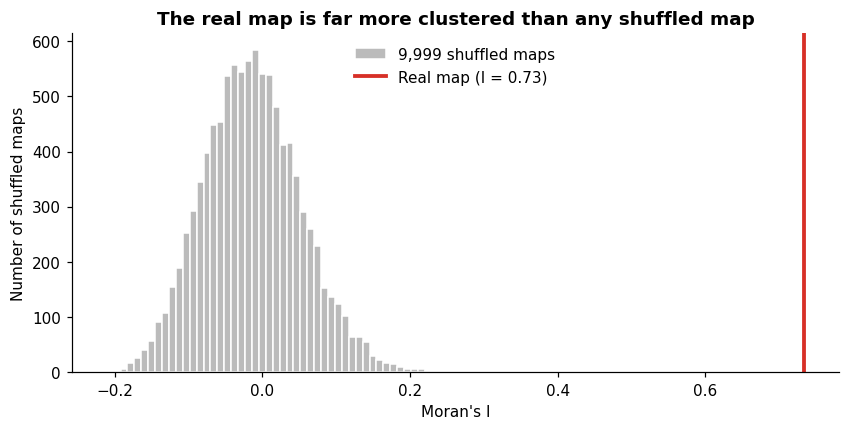

**What it shows.** Moran's I is **0.73**. None of the 9,999 shuffled maps came close (the
highest was 0.26), so the p-value is 0.0001, the smallest this test can report. Option 2
support is strongly clustered: ridings with high support tend to border other high-support ridings, and low
next to low.

In [7]:
W = queen_weights(gdf)
i_obs, p_obs, i_perm = moran_test(y, W, N_PERMUTATIONS)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(i_perm, bins=50, color="#bbbbbb", edgecolor="white", label="9,999 shuffled maps")
ax.axvline(i_obs, color="#d73027", linewidth=2.5, label=f"Real map (I = {i_obs:.2f})")
ax.set_xlabel("Moran's I")
ax.set_ylabel("Number of shuffled maps")
ax.set_title("The real map is far more clustered than any shuffled map")
ax.legend(frameon=False)
plt.show()

note(f"""**What it shows.** Moran's I is **{i_obs:.2f}**. None of the {N_PERMUTATIONS:,} shuffled maps came close (the
highest was {i_perm.max():.2f}), so the p-value is {p_obs:.4f}, the smallest this test can report. Option 2
support is strongly clustered: ridings with high support tend to border other high-support ridings, and low
next to low.""")

**Does the answer depend on how we define "neighbour"?** Below, the same statistic is computed with other definitions: each riding's 3, 5, 7 or 10 nearest ridings (measured centre to centre). If the conclusion held only for one definition, it would be fragile.

In [8]:
xy = gdf[["x", "y"]].to_numpy()
sens = {"Shared border (main result)": i_obs}
sens.update({f"{k} nearest ridings": morans_i(y, knn_weights(xy, k)) for k in (3, 5, 7, 10)})
sens = pd.Series(sens, name="Moran's I").round(2)
note(f"""**What it shows.** Every definition gives a clearly positive value, from {sens.min():.2f} to
{sens.max():.2f}. Values fall as more distant ridings are counted as neighbours, which is expected:
the further apart two ridings are, the less alike they tend to be. The conclusion does not depend on the choice.""")
sens.to_frame()

**What it shows.** Every definition gives a clearly positive value, from 0.49 to
0.73. Values fall as more distant ridings are counted as neighbours, which is expected:
the further apart two ridings are, the less alike they tend to be. The conclusion does not depend on the choice.

,Moran's I
Shared border (main result),0.73
3 nearest ridings,0.67
5 nearest ridings,0.64
7 nearest ridings,0.57
10 nearest ridings,0.49


## 6. Is it just city versus country?
Sections 2 to 4 showed large gaps between regions. City ridings border city ridings and rural ridings border rural ridings, so the clustering in section 5 could simply be the urban-rural divide. To check, we subtract each region's average from its ridings' results and repeat the test on what is left. A riding then counts as "high" only if it is high **for its region**.

In [9]:
region_mean = gdf.groupby("region")["option2_pct"].transform("mean").to_numpy()
resid = y - region_mean
i_res, p_res, _ = moran_test(resid, W, N_PERMUTATIONS)

verdict = ("some clustering remains beyond the regional averages, though it is weak"
           if p_res < ALPHA else "no clear clustering remains once regional averages are removed")
note(f"""**What it shows.** After removing regional averages, Moran's I drops from {i_obs:.2f} to **{i_res:.2f}**
(p = {p_res:.3f}). Most of the clustering is the difference between regions: {verdict}. In other words,
knowing a riding's region tells you most of what its neighbours tell you. This depends on the region labels,
which have not been independently verified.""")

**What it shows.** After removing regional averages, Moran's I drops from 0.73 to **0.11**
(p = 0.033). Most of the clustering is the difference between regions: some clustering remains beyond the regional averages, though it is weak. In other words,
knowing a riding's region tells you most of what its neighbours tell you. This depends on the region labels,
which have not been independently verified.

## 7. Where are the clusters?
Moran's I describes the whole map. To see **which** ridings drive it, we compute a local version for each riding (often called **LISA**) and sort ridings into four groups:

- **High-High** (red): high Option 2, surrounded by high Option 2. A hotspot.
- **Low-Low** (dark blue): low Option 2, surrounded by low. A coldspot.
- **High-Low** (orange): high Option 2, surrounded by low. An outlier.
- **Low-High** (light blue): low Option 2, surrounded by high. An outlier.

Each riding is tested with the same shuffling idea as section 5: its neighbours are replaced by random ridings 9,999 times. Ridings whose pattern could easily be chance (p ≥ 0.05) are grey. Groups with no significant ridings are left out of the legend.

The first figure maps the results, with Calgary and Edmonton enlarged because their ridings are too small to see on the provincial map. **How to read the second figure.** Each dot is a riding. Left to right is the riding's own Option 2 result; bottom to top is its neighbours' average. Both are in standard units, where 0 is the average riding. Dots in the top-right are hotspots, bottom-left are coldspots.

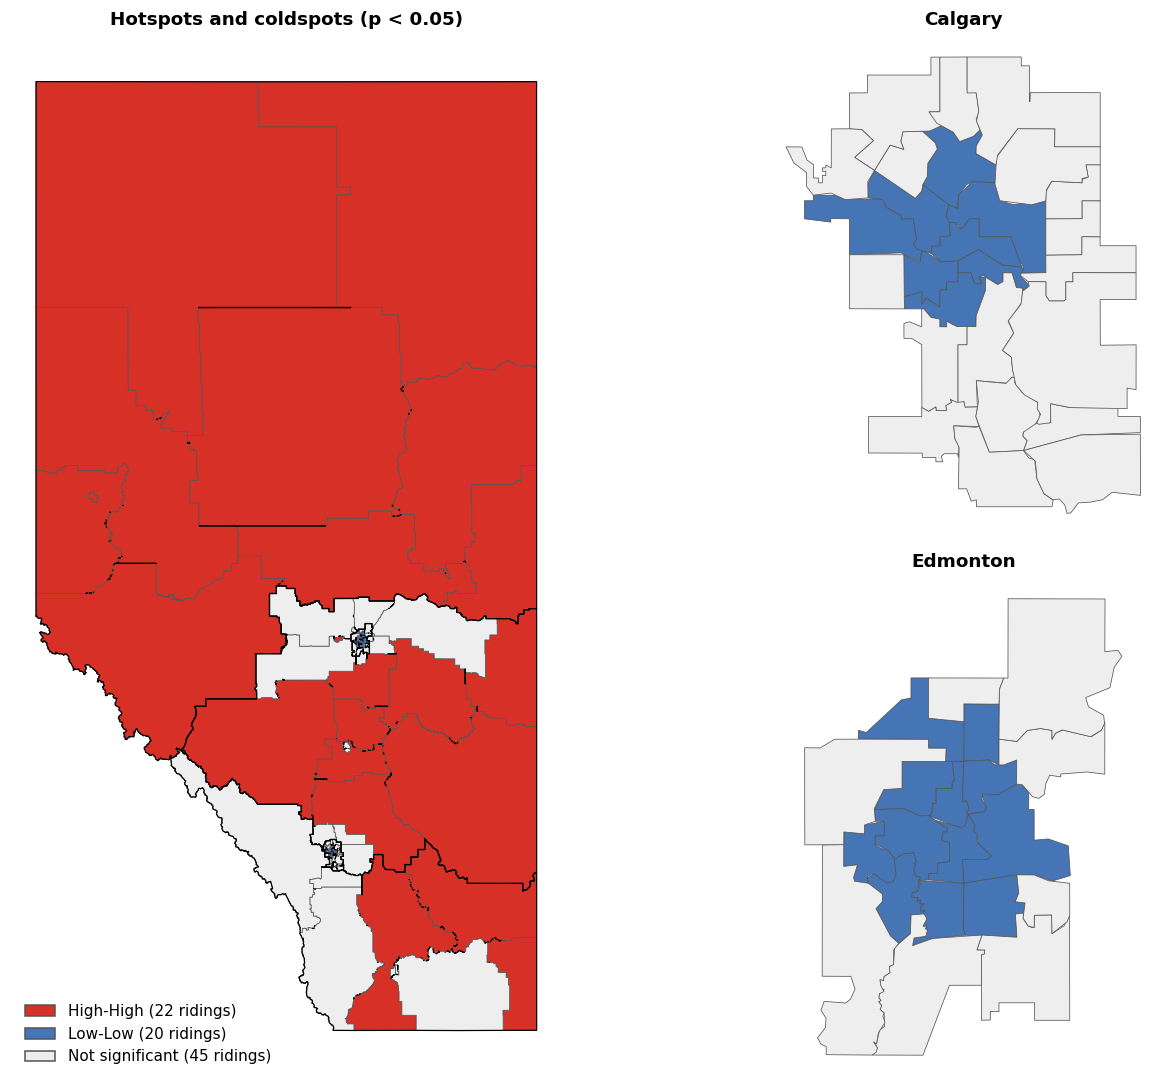

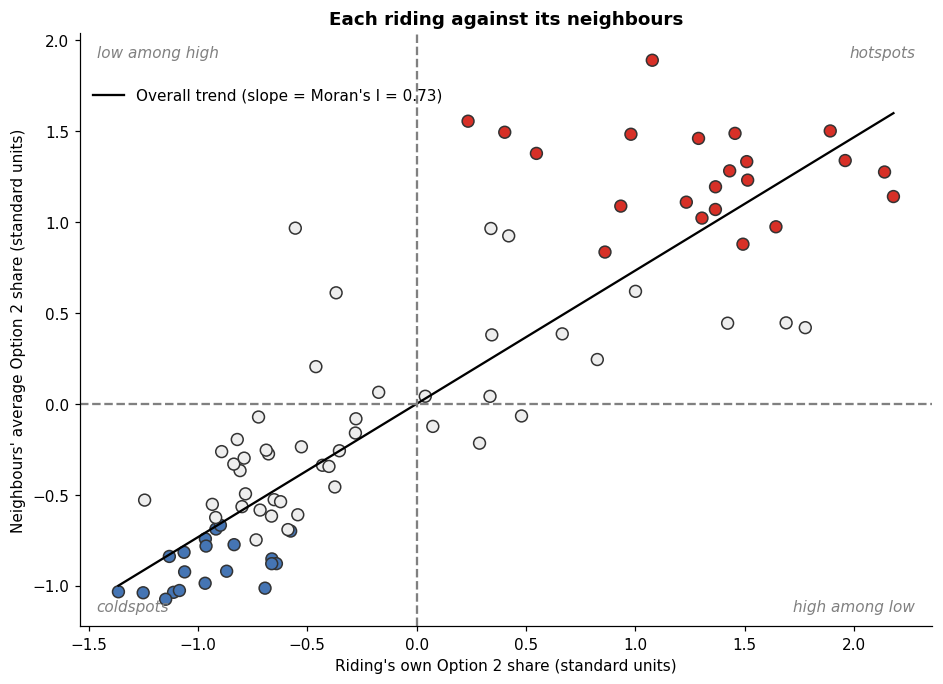

**What it shows.** 22 ridings are **hotspots** (North 10, Central 9, South 3). They form one large area
covering every northern riding, rural central Alberta, and the southeast around Medicine Hat and Brooks.
20 are **coldspots** (Edmonton 12, Calgary 8), mostly the central and older parts of both cities; the newer
outer city ridings are not significant. No riding is a significant outlier. The remaining 45 ridings
show no pattern beyond chance. They include the suburbs and towns around both cities, Red Deer, Lethbridge
and the southwest foothills, which sit between the high and low areas.

**Caution.** With 87 separate tests at the 5% level, about 4 ridings could be flagged by chance alone, so treat
individual borderline ridings with care. The broad picture (rural hotspots, urban coldspots) is robust.

In [10]:
lisa = local_moran(y, W, N_PERMUTATIONS)
gdf["lisa"] = np.where(lisa["p"] < ALPHA, lisa["quadrant"], "Not significant")
gdf["lisa_p"] = lisa["p"].to_numpy()

present = [name for name in LISA_COLOURS if (gdf["lisa"] == name).any()]

fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1.0])
ax_map, ax_cal, ax_edm = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
for ax, sub_gdf in ((ax_map, gdf), (ax_cal, gdf[gdf["region"] == "Calgary"]), (ax_edm, gdf[gdf["region"] == "Edmonton"])):
    for name in present:
        part = sub_gdf[sub_gdf["lisa"] == name]
        if len(part):
            part.plot(color=LISA_COLOURS[name], edgecolor="#555555", linewidth=0.5, ax=ax)
    ax.set_axis_off()
gdf.dissolve("region").boundary.plot(ax=ax_map, color="black", linewidth=0.8)
ax_map.legend(handles=[mpatches.Patch(facecolor=LISA_COLOURS[n], edgecolor="#555555",
                                      label=f"{n} ({(gdf['lisa'] == n).sum()} ridings)") for n in present],
              loc="lower left", frameon=False)
ax_map.set_title("Hotspots and coldspots (p < 0.05)")
ax_cal.set_title("Calgary")
ax_edm.set_title("Edmonton")
plt.tight_layout()
plt.show()

fig, ax_sc = plt.subplots(figsize=(10, 7))
colours = gdf["lisa"].map(LISA_COLOURS)
ax_sc.scatter(lisa["z"], lisa["lag"], c=colours, s=60, edgecolor="#333333")
xs = np.linspace(lisa["z"].min(), lisa["z"].max(), 20)
ax_sc.plot(xs, i_obs * xs, color="black", linewidth=1.5, label=f"Overall trend (slope = Moran's I = {i_obs:.2f})")
ax_sc.axhline(0, color="grey", linestyle="--")
ax_sc.axvline(0, color="grey", linestyle="--")
for (tx, ty, label) in ((0.98, 0.98, "hotspots"), (0.02, 0.02, "coldspots"), (0.98, 0.02, "high among low"),
                        (0.02, 0.98, "low among high")):
    ax_sc.text(tx, ty, label, transform=ax_sc.transAxes, ha="right" if tx > 0.5 else "left",
               va="top" if ty > 0.5 else "bottom", color="grey", fontsize=10, style="italic")
ax_sc.set_xlabel("Riding's own Option 2 share (standard units)")
ax_sc.set_ylabel("Neighbours' average Option 2 share (standard units)")
ax_sc.set_title("Each riding against its neighbours")
ax_sc.legend(loc="upper left", bbox_to_anchor=(0, 0.93), frameon=False)
plt.show()

counts = gdf["lisa"].value_counts()
hh = gdf[gdf["lisa"] == "High-High"]
ll = gdf[gdf["lisa"] == "Low-Low"]
outl = gdf[gdf["lisa"].isin(["High-Low", "Low-High"])]
def by_region(frame):
    return ", ".join(f"{r} {n}" for r, n in frame["region"].value_counts().items())
outlier_text = ("No riding is a significant outlier." if outl.empty else
                f"{len(outl)} ridings are significant outliers: {', '.join(outl['ed_name'].str.title())}.")
note(f"""**What it shows.** {len(hh)} ridings are **hotspots** ({by_region(hh)}). They form one large area
covering every northern riding, rural central Alberta, and the southeast around Medicine Hat and Brooks.
{len(ll)} are **coldspots** ({by_region(ll)}), mostly the central and older parts of both cities; the newer
outer city ridings are not significant. {outlier_text} The remaining {counts.get('Not significant', 0)} ridings
show no pattern beyond chance. They include the suburbs and towns around both cities, Red Deer, Lethbridge
and the southwest foothills, which sit between the high and low areas.

**Caution.** With 87 separate tests at the 5% level, about 4 ridings could be flagged by chance alone, so treat
individual borderline ridings with care. The broad picture (rural hotspots, urban coldspots) is robust.""")

## 8. Did turnout matter?
Turnout is the share of registered electors who cast a ballot. One common idea is that motivated voters turn out more, so higher turnout could go with higher Option 2 support, or lower. Each dot below is a riding.

**Two cautions.** First, this compares ridings, not people: it cannot say whether Option 2 voters themselves were more likely to vote. Second, turnout here uses the elector counts printed in the Elections Alberta workbooks, which are higher than the counts in the news release, so all turnouts are a few points lower than the official headline figure (see `other/sources.md`).

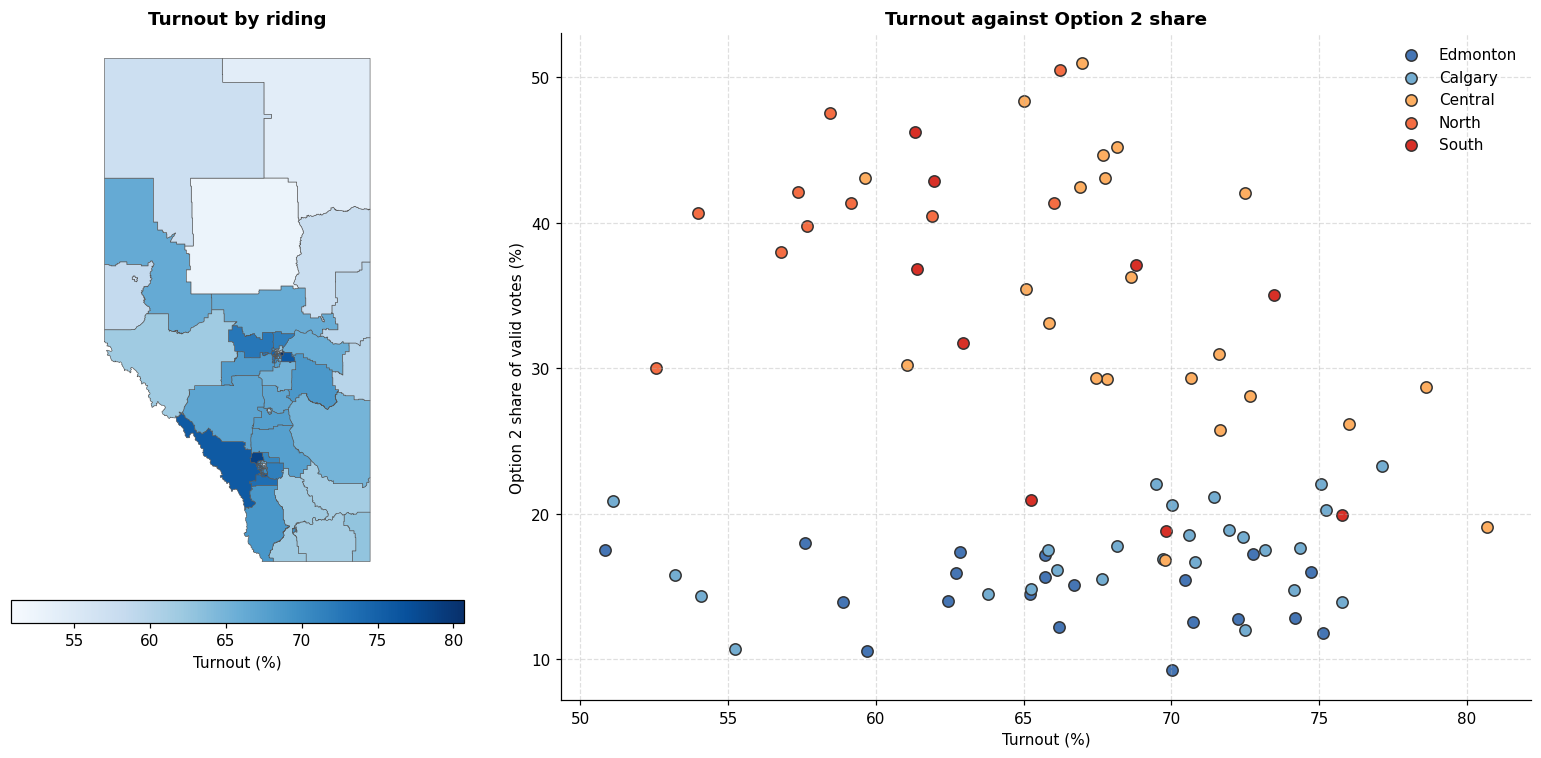

**What it shows.** Turnout ranged from 50.8% (Edmonton-Decore) to
80.7% (Sherwood Park). By region, median turnout was lowest in the
North (58.0%) and highest in Calgary (70.3%). Across all ridings the rank correlation between turnout
and Option 2 share is **-0.18** (it runs from -1 to 1, with 0 meaning no relationship), which is weak.
Within regions, the relationship is sometimes moderately strong but points in opposite directions: higher turnout
goes with more Option 2 support in some regions and less in others (table below). Each region has only 9 to 26
ridings, so these within-region figures are fragile. There is **no clear, consistent link** between turnout and
Option 2 support.

,Rank correlation
Edmonton,-0.32
Calgary,0.31
Central,-0.62
North,0.61
South,-0.70


In [11]:
fig, (ax_map, ax_sc) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [0.8, 1.2]})
gdf.plot(column="turnout_pct", cmap="Blues", edgecolor="#555555", linewidth=0.4, ax=ax_map, legend=True,
         legend_kwds={"label": "Turnout (%)", "orientation": "horizontal", "shrink": 0.7, "pad": 0.02})
ax_map.set_title("Turnout by riding")
ax_map.set_axis_off()

for region in REGION_ORDER:
    sub = gdf[gdf["region"] == region]
    ax_sc.scatter(sub["turnout_pct"], sub["option2_pct"], color=REGION_COLOURS[region], s=55,
                  edgecolor="#333333", label=region)
ax_sc.set_xlabel("Turnout (%)")
ax_sc.set_ylabel("Option 2 share of valid votes (%)")
ax_sc.set_title("Turnout against Option 2 share")
ax_sc.legend(frameon=False)
ax_sc.grid(linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

rho_all = gdf[["turnout_pct", "option2_pct"]].corr(method="spearman").iloc[0, 1]
rho_reg = pd.Series({r: gdf.loc[gdf["region"] == r, ["turnout_pct", "option2_pct"]].corr(method="spearman").iloc[0, 1]
                     for r in REGION_ORDER}, name="Rank correlation").round(2)
low_t = gdf.loc[gdf["turnout_pct"].idxmin()]
high_t = gdf.loc[gdf["turnout_pct"].idxmax()]
t_med = gdf.groupby("region")["turnout_pct"].median()
note(f"""**What it shows.** Turnout ranged from {pct(low_t['turnout_pct'])} ({low_t['ed_name'].title()}) to
{pct(high_t['turnout_pct'])} ({high_t['ed_name'].title()}). By region, median turnout was lowest in the
{t_med.idxmin()} ({pct(t_med.min())}) and highest in {t_med.idxmax()} ({pct(t_med.max())}). Across all ridings the rank correlation between turnout
and Option 2 share is **{rho_all:.2f}** (it runs from -1 to 1, with 0 meaning no relationship), which is weak.
Within regions, the relationship is sometimes moderately strong but points in opposite directions: higher turnout
goes with more Option 2 support in some regions and less in others (table below). Each region has only 9 to 26
ridings, so these within-region figures are fragile. There is **no clear, consistent link** between turnout and
Option 2 support.""")
rho_reg.to_frame()

## 9. Summary of findings

In [12]:
note(f"""1. **Option 2 lost province-wide** with {pct(prov_share, 2)} of valid votes and won a majority in only
   {len(over_50)} of 87 ridings ({', '.join(over_50['ed_name'].str.title())}), both just over 50%.
2. **Support was strongest in rural Alberta and weakest in the two big cities.** Median ridings ranged from
   {pct(med.min())} ({med.idxmin()}) to {pct(med.max())} ({med.idxmax()}).
3. **The map overstates Option 2.** Rural ridings dominate the map's area, but Calgary and Edmonton cast
   {pct(cities['Share of all valid votes'], 0)} of all valid votes.
4. **Support is strongly clustered** (Moran's I = {i_obs:.2f}, p = {p_obs:.4f}), and this holds for every definition
   of "neighbour" we tried.
5. **Most of that clustering is the difference between regions.** Within regions, clustering is much weaker
   (I = {i_res:.2f}, p = {p_res:.3f}).
6. **{len(hh)} ridings outside the cities form significant hotspots** and {len(ll)} city ridings form
   significant coldspots.
7. **Turnout shows no consistent relationship** with Option 2 support (rank correlation {rho_all:.2f}).""")

1. **Option 2 lost province-wide** with 25.05% of valid votes and won a majority in only
   2 of 87 ridings (Rimbey-Rocky Mountain House-Sundre, Central Peace-Notley), both just over 50%.
2. **Support was strongest in rural Alberta and weakest in the two big cities.** Median ridings ranged from
   14.8% (Edmonton) to 41.0% (North).
3. **The map overstates Option 2.** Rural ridings dominate the map's area, but Calgary and Edmonton cast
   52% of all valid votes.
4. **Support is strongly clustered** (Moran's I = 0.73, p = 0.0001), and this holds for every definition
   of "neighbour" we tried.
5. **Most of that clustering is the difference between regions.** Within regions, clustering is much weaker
   (I = 0.11, p = 0.033).
6. **22 ridings outside the cities form significant hotspots** and 20 city ridings form
   significant coldspots.
7. **Turnout shows no consistent relationship** with Option 2 support (rank correlation -0.18).

## Limitations and next steps
**What this analysis does not show.**
- **Why** places voted as they did. There are no explanatory variables yet (income, industry, age, past party vote). The original notebook included a regression, but its explanatory variables were randomly generated, so it was removed.
- **How individuals voted.** All results are for ridings. A pattern across ridings need not hold for the people in them.

**Known weaknesses.**
- The region labels have not been checked against an official source, and sections 3, 4, 6 and 8 depend on them.
- Boundary lines are simplified. This does not change which ridings border each other in any way that matters here, but the maps are not survey-grade.

**Next steps.**
- Verify the region labels, or replace them with an official grouping.
- Add real explanatory data, for example Statistics Canada census profiles by electoral division or 2023 provincial election results, and then fit a spatial regression.
- Repeat the analysis for the other nine questions to see whether the same geography appears.

## Glossary
- **Riding / electoral division.** One of Alberta's 87 districts that each elect one MLA. Results are reported by riding.
- **Option 2 share.** Option 2 votes divided by Option 1 + Option 2 votes, as a percentage. Declined and rejected ballots are excluded.
- **Region.** One of five groups of ridings used here: Calgary, Edmonton (city ridings only), Central, North and South.
- **Neighbours.** Ridings that share a border. Section 5 also tries "the k nearest ridings".
- **Moran's I.** One number summarising how alike neighbouring ridings are. About 0 means no pattern; closer to 1 means neighbours are very alike; negative means neighbours tend to differ.
- **Permutation test / shuffling.** Randomly reassigning the results to ridings many times to see what a map with no geographic pattern looks like, then comparing the real map with those shuffled maps.
- **p-value.** The share of shuffled maps that looked at least as clustered as the real one. Small values (below 0.05 here) mean the pattern is unlikely to be chance. With 9,999 shuffles, the smallest possible value is 0.0001.
- **LISA (local Moran's I).** A version of Moran's I for each riding, used to label hotspots, coldspots and outliers.
- **Standard units.** A value's distance from the average riding, measured in standard deviations. 0 is average; +1 is one standard deviation above.
- **Rank correlation (Spearman).** How consistently one measure rises as another rises, from -1 (always falls) through 0 (no relationship) to 1 (always rises).